# Final classification: data split, PCA and classification with SVM, XGBoost and Random Forest


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import balanced_accuracy_score, f1_score, mean_absolute_error, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, recall_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

DATA_DIR = Path(".")
FEATURES_DIR = DATA_DIR / "dataset2d_features_slices"
METADATA_FILE = DATA_DIR / "dataset2d_meta.pkl"
RANDOM_SEED = 42

## 1. Load and validate aligned slice data
Feature rows must align to metadata `row_idx`; this catches mixing different runs.

In [3]:
if not FEATURES_DIR.is_dir():
    raise FileNotFoundError(f"Missing feature folder: {FEATURES_DIR.resolve()}. Set DATA_DIR to the output directory.")
if not METADATA_FILE.is_file():
    raise FileNotFoundError(f"Missing metadata: {METADATA_FILE.resolve()}. Set DATA_DIR to the output directory.")
meta = pd.read_pickle(METADATA_FILE).reset_index(drop=True)
assert "row_idx" in meta and np.array_equal(meta.row_idx.to_numpy(), np.arange(len(meta))), "row_idx is not aligned"

features = np.empty((len(meta), 2048), dtype=np.float32)
for row_idx, row in meta.iterrows():
    nodule_id = str(row.nodule_id)
    slice_idx = int(row.slice_idx)
    slice_path = FEATURES_DIR / f"{nodule_id}_slice{slice_idx:04d}.npz"
    if not slice_path.is_file():
        raise FileNotFoundError(f"Missing feature record for row {row_idx}: {slice_path.resolve()}")
    with np.load(slice_path, allow_pickle=False) as slice_data:
        assert str(slice_data["nodule_id"].item()) == nodule_id, f"Nodule ID mismatch: {slice_path}"
        assert int(slice_data["slice_idx"].item()) == slice_idx, f"Slice index mismatch: {slice_path}"
        feature = slice_data["feature_vector"]
        assert feature.shape == (2048,), f"Unexpected feature shape in {slice_path}: {feature.shape}"
        features[row_idx] = feature

assert features.ndim == 2 and features.shape[1] == 2048, f"Unexpected feature shape: {features.shape}"
assert len(features) == len(meta), "Feature/metadata row counts differ"
required = {"patient_id", "nodule_id", "slice_idx", "slice_in_nodule", "nodule_idx", "n_annotators", "malignancy"}
assert required.issubset(meta.columns), f"Missing columns: {required - set(meta.columns)}"
assert np.isfinite(features).all(), "Features contain NaN/Inf"
assert not meta.duplicated(["nodule_id", "slice_idx"]).any(), "Duplicate slice identifiers"
print(f"Features loaded from {FEATURES_DIR}: {features.shape}, dtype={features.dtype}")
print(f"Slices: {len(meta):,}; nodules: {meta.nodule_id.nunique():,}; patients: {meta.patient_id.nunique():,}")
print("Example ratings:", meta.iloc[0].malignancy)

Features loaded from dataset2d_features_slices: (21381, 2048), dtype=float32
Slices: 21,381; nodules: 2,279; patients: 745
Example ratings: [5, 5, 5, 4]


## 2. Assemble variable-length nodule bags

`bags[nodule_id]` stores feature-row indices in slice order. Retrieve a bag as `features[bags[nodule_id]]`, with shape `(slices, 2048)`. Ratings are represented once per nodule below.

In [4]:
def rating_vector(value, n_annotators, nodule_id):
    ratings = np.asarray(value).reshape(-1)
    if len(ratings) != int(n_annotators):
        raise ValueError(f"{nodule_id}: {len(ratings)} ratings but n_annotators={n_annotators}")
    if not np.isin(ratings, [1, 2, 3, 4, 5]).all():
        raise ValueError(f"{nodule_id}: expected ratings in 1..5, got {ratings}")
    return ratings.astype(np.int64)

bags, records = {}, []
for nodule_id, group in meta.groupby("nodule_id", sort=False):
    group = group.sort_values(["slice_in_nodule", "slice_idx"])
    patients, nodule_indices = group.patient_id.astype(str).unique(), group.nodule_idx.unique()
    assert len(patients) == len(nodule_indices) == 1, f"Inconsistent IDs: {nodule_id}"
    rows = group.row_idx.to_numpy(dtype=np.int64)
    bags[nodule_id] = rows
    ratings = rating_vector(group.iloc[0].malignancy, group.iloc[0].n_annotators, nodule_id)
    for repeated in group.malignancy.iloc[1:]:
        assert np.array_equal(np.asarray(repeated).reshape(-1), ratings), f"Ratings vary across slices: {nodule_id}"
    votes = np.bincount(ratings - 1, minlength=5)
    records.append({"nodule_id": nodule_id, "patient_id": patients[0],
        "nodule_idx": int(nodule_indices[0]), "n_slices": len(rows),
        "n_annotators": int(group.iloc[0].n_annotators),
        "malignancy_ratings": ratings.tolist(),
        "malignancy_vote_counts_1_to_5": votes.tolist(),
        "malignancy_vote_distribution_1_to_5": (votes / votes.sum()).tolist()})
nodules = pd.DataFrame(records).sort_values("nodule_idx").reset_index(drop=True)
assert len(nodules) == meta.nodule_id.nunique()
assert sum(map(len, bags.values())) == len(features)
display(nodules.n_slices.describe())
display(nodules[["nodule_id", "patient_id", "n_slices", "malignancy_ratings", "malignancy_vote_distribution_1_to_5"]].head())


count    2279.000000
mean        9.381746
std         4.721194
min         5.000000
25%         7.000000
50%         8.000000
75%        10.000000
max        49.000000
Name: n_slices, dtype: float64

,nodule_id,patient_id,n_slices,malignancy_ratings,malignancy_vote_distribution_1_to_5
0,LIDC-IDRI-0001_nodule00,LIDC-IDRI-0001,12,"[5, 5, 5, 4]","[0.0, 0.0, 0.0, 0.25, 0.75]"
1,LIDC-IDRI-0002_nodule00,LIDC-IDRI-0002,32,"[5, 4]","[0.0, 0.0, 0.0, 0.5, 0.5]"
2,LIDC-IDRI-0003_nodule00,LIDC-IDRI-0003,12,[2],"[0.0, 1.0, 0.0, 0.0, 0.0]"
3,LIDC-IDRI-0003_nodule01,LIDC-IDRI-0003,11,"[5, 5, 3, 4]","[0.0, 0.0, 0.25, 0.25, 0.5]"
4,LIDC-IDRI-0003_nodule02,LIDC-IDRI-0003,8,"[4, 4, 3, 2]","[0.0, 0.25, 0.25, 0.5, 0.0]"


In [5]:
example_id = nodules.iloc[0].nodule_id
example_bag = np.asarray(features[bags[example_id]])
print(example_id, example_bag.shape)  # (slices, 2048)

LIDC-IDRI-0001_nodule00 (12, 2048)


## 3. Create patient-disjoint train/validation/test splits

Reproducible grouped random split (not stratified). Group by patient; proportions are approximate because patients contribute different numbers of nodules.

In [6]:
# Shuffle unique patient IDs, then assign whole patients to each split.
# This is a grouped random split, not stratified by labels.

groups = nodules.patient_id.astype(str).to_numpy()
unique_patients = np.unique(groups)
rng = np.random.default_rng(RANDOM_SEED)
shuffled_patients = rng.permutation(unique_patients)

n_test_patients = max(1, int(round(0.15 * len(shuffled_patients))))
test_patients = set(shuffled_patients[:n_test_patients])
remaining_patients = shuffled_patients[n_test_patients:]
n_val_patients = max(1, int(round((0.15 / 0.85) * len(remaining_patients))))

val_patients = set(remaining_patients[:n_val_patients])
train_patients = set(remaining_patients[n_val_patients:])

train_idx = np.flatnonzero(np.isin(groups, list(train_patients)))
val_idx = np.flatnonzero(np.isin(groups, list(val_patients)))
test_idx = np.flatnonzero(np.isin(groups, list(test_patients)))

patient_sets = {"train": train_patients, "validation": val_patients, "test": test_patients}
assert patient_sets["train"].isdisjoint(patient_sets["validation"])
assert patient_sets["train"].isdisjoint(patient_sets["test"])
assert patient_sets["validation"].isdisjoint(patient_sets["test"])
assert len(np.unique(np.r_[train_idx, val_idx, test_idx])) == len(nodules)

split = np.full(len(nodules), "", dtype=object)
split[train_idx], split[val_idx], split[test_idx] = "train", "validation", "test"
nodules["split"] = split
summary = nodules.groupby("split").agg(nodules=("nodule_id", "size"), patients=("patient_id", "nunique"), slices=("n_slices", "sum"))
summary["nodule_fraction"] = summary.nodules / len(nodules)
display(summary)


,nodules,patients,slices,nodule_fraction
split,,,,
test,346,112,3153,0.151821
train,1595,521,15043,0.699868
validation,338,112,3185,0.148311


### Reuse the split
Indices here select slice-feature rows, while the assignment is at nodule level. Never randomly split slices.

In [7]:
def slice_rows_for(split_name):
    ids = nodules.loc[nodules.split == split_name, "nodule_id"]
    return np.concatenate([bags[nodule_id] for nodule_id in ids])

train_slice_rows = slice_rows_for("train")
validation_slice_rows = slice_rows_for("validation")
test_slice_rows = slice_rows_for("test")

for name, rows in [("train", train_slice_rows), ("validation", validation_slice_rows), ("test", test_slice_rows)]:
    assert set(meta.iloc[rows].patient_id.astype(str)) == patient_sets[name]
    
print("Slice rows:", len(train_slice_rows), len(validation_slice_rows), len(test_slice_rows))
split_path = DATA_DIR / "dataset2d_patient_splits.csv"
nodules.to_csv(split_path, index=False)
print("Saved reusable nodule split:", split_path.resolve())


Slice rows: 15043 3185 3153
Saved reusable nodule split: C:\Users\franc\Desktop\LungCT\data-analysis\dataset2d_patient_splits.csv


### Label mappings and task-specific splits

All tasks reuse the same patient-disjoint train/validation/test assignment. Binary labels use mean malignancy < 3 as benign (0), > 3 as malignant (1), and exclude exactly 3. Three-class labels keep exactly 3 as inconclusive (2). Five-class labels round the mean malignancy rating to the nearest integer from 1 to 5 (half values round up). Each task has its own `x_train_*`, `y_train_*`, `x_val_*`, `y_val_*`, `x_test_*`, and `y_test_*` arrays.

#### a) Binary classification

In [8]:
mean_malignancy = nodules.malignancy_ratings.apply(np.mean).to_numpy()
labels_all = np.where(mean_malignancy > 3, 1,
                      np.where(mean_malignancy < 3, 0, -1))  # -1 = indeterminate
labels_3 = np.where(mean_malignancy == 3, 2,
                    np.where(mean_malignancy < 3, 0, 1))  # 0=benign, 1=malignant, 2=inconclusive
labels_5 = np.floor(mean_malignancy + 0.5).astype(np.int64)  # nearest rating, ties round up

nodules["mean_malignancy"] = mean_malignancy
nodules["label"] = labels_all
nodules["label_3"] = labels_3
nodules["label_5"] = labels_5

# Mean-pool slice features of each nodule bag
X_all = np.stack([np.asarray(features[bags[nid]]).mean(axis=0) for nid in nodules.nodule_id]).astype(np.float32)
keep = labels_all != -1
print(f"Excluded indeterminate nodules from binary task (mean rating == 3): {(~keep).sum()}")

def make_task_splits(labels, include_mask):
    split_values = nodules.split.to_numpy()
    split_data = []
    for split_name in ("train", "validation", "test"):
        mask = (split_values == split_name) & include_mask
        split_data.append((X_all[mask], labels[mask]))
    return split_data

# Binary dataset
(   (X_train_binary, y_train_binary),
    (X_val_binary, y_val_binary),
    (X_test_binary, y_test_binary),
) = make_task_splits(labels_all, keep)

# 3-class dataset
(   (X_train_3, y_train_3),
    (X_val_3, y_val_3),
    (X_test_3, y_test_3),
) = make_task_splits(labels_3, np.ones(len(labels_3), dtype=bool))

# 5-class dataset
(   (X_train_5, y_train_5),
    (X_val_5, y_val_5),
    (X_test_5, y_test_5),
) = make_task_splits(labels_5, np.ones(len(labels_5), dtype=bool))

assert sum(len(y) for _, y in make_task_splits(labels_3, np.ones(len(labels_3), dtype=bool))) == len(nodules)
assert sum(len(y) for _, y in make_task_splits(labels_5, np.ones(len(labels_5), dtype=bool))) == len(nodules)
assert sum(len(y) for _, y in make_task_splits(labels_all, keep)) == int(keep.sum())

for task_name, task_splits in [
    ("binary", [(X_train_binary, y_train_binary), (X_val_binary, y_val_binary), (X_test_binary, y_test_binary)]),
    ("3-class", [(X_train_3, y_train_3), (X_val_3, y_val_3), (X_test_3, y_test_3)]),
    ("5-class", [(X_train_5, y_train_5), (X_val_5, y_val_5), (X_test_5, y_test_5)]),
]:
    print(f"{task_name:>8}: " + "  ".join(
        f"{name} n={len(y)} classes={dict(zip(*np.unique(y, return_counts=True)))}"
        for name, (_, y) in zip(("train", "validation", "test"), task_splits)
    ))

Excluded indeterminate nodules from binary task (mean rating == 3): 561
  binary: train n=1204 classes={np.int64(0): np.int64(796), np.int64(1): np.int64(408)}  validation n=261 classes={np.int64(0): np.int64(178), np.int64(1): np.int64(83)}  test n=253 classes={np.int64(0): np.int64(178), np.int64(1): np.int64(75)}
 3-class: train n=1595 classes={np.int64(0): np.int64(796), np.int64(1): np.int64(408), np.int64(2): np.int64(391)}  validation n=338 classes={np.int64(0): np.int64(178), np.int64(1): np.int64(83), np.int64(2): np.int64(77)}  test n=346 classes={np.int64(0): np.int64(178), np.int64(1): np.int64(75), np.int64(2): np.int64(93)}
 5-class: train n=1595 classes={np.int64(1): np.int64(166), np.int64(2): np.int64(353), np.int64(3): np.int64(761), np.int64(4): np.int64(243), np.int64(5): np.int64(72)}  validation n=338 classes={np.int64(1): np.int64(35), np.int64(2): np.int64(85), np.int64(3): np.int64(151), np.int64(4): np.int64(55), np.int64(5): np.int64(12)}  test n=346 classes=

## 4. PCA to reduce the features' dimensionatity

### 4.1. Binary

PCA: 2048 -> 219 components (94.96% variance explained)


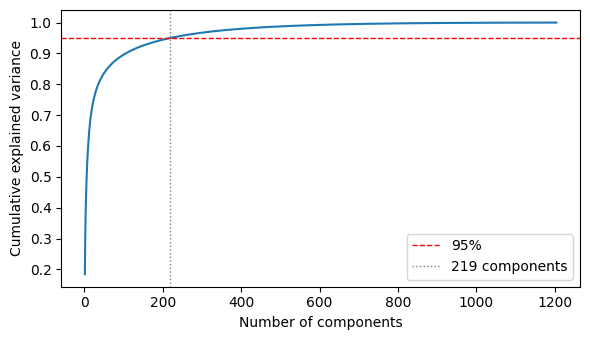

In [9]:
scaler = StandardScaler().fit(X_train_binary)
X_train_scaled = scaler.transform(X_train_binary)
X_val_scaled = scaler.transform(X_val_binary)
X_test_scaled = scaler.transform(X_test_binary)

# PCA: keep enough components to explain 95% of the training variance
VARIANCE_TARGET = 0.95
pca_full = PCA(random_state=RANDOM_SEED).fit(X_train_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cumulative, VARIANCE_TARGET) + 1)

pca = PCA(n_components=n_components, random_state=RANDOM_SEED).fit(X_train_scaled)
X_train_pca_binary = pca.transform(X_train_scaled)
X_val_pca_binary = pca.transform(X_val_scaled)
X_test_pca_binary = pca.transform(X_test_scaled)
print(f"PCA: 2048 -> {n_components} components "
      f"({pca.explained_variance_ratio_.sum():.2%} variance explained)")

plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative)
plt.axhline(VARIANCE_TARGET, color="r", ls="--", lw=1, label=f"{VARIANCE_TARGET:.0%}")
plt.axvline(n_components, color="gray", ls=":", lw=1, label=f"{n_components} components")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.legend(); plt.tight_layout(); plt.show()

### 4.2. 3-class

PCA: 2048 -> 241 components (94.96% variance explained)


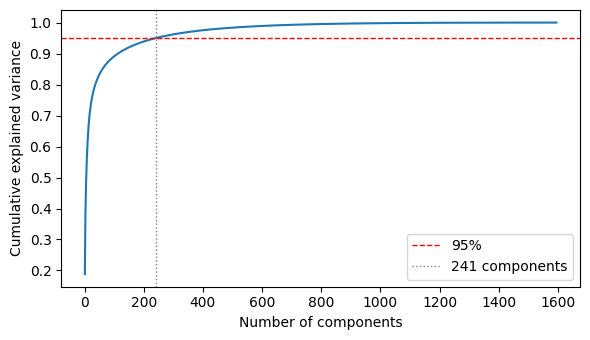

In [10]:
scaler = StandardScaler().fit(X_train_3)
X_train_scaled = scaler.transform(X_train_3)
X_val_scaled = scaler.transform(X_val_3)
X_test_scaled = scaler.transform(X_test_3)

# PCA: keep enough components to explain 95% of the training variance
VARIANCE_TARGET = 0.95
pca_full = PCA(random_state=RANDOM_SEED).fit(X_train_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cumulative, VARIANCE_TARGET) + 1)

pca = PCA(n_components=n_components, random_state=RANDOM_SEED).fit(X_train_scaled)
X_train_pca_3 = pca.transform(X_train_scaled)
X_val_pca_3 = pca.transform(X_val_scaled)
X_test_pca_3 = pca.transform(X_test_scaled)
print(f"PCA: 2048 -> {n_components} components "
      f"({pca.explained_variance_ratio_.sum():.2%} variance explained)")

plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative)
plt.axhline(VARIANCE_TARGET, color="r", ls="--", lw=1, label=f"{VARIANCE_TARGET:.0%}")
plt.axvline(n_components, color="gray", ls=":", lw=1, label=f"{n_components} components")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.legend(); plt.tight_layout(); plt.show()

### 4.3. 5-class

PCA: 2048 -> 241 components (94.96% variance explained)


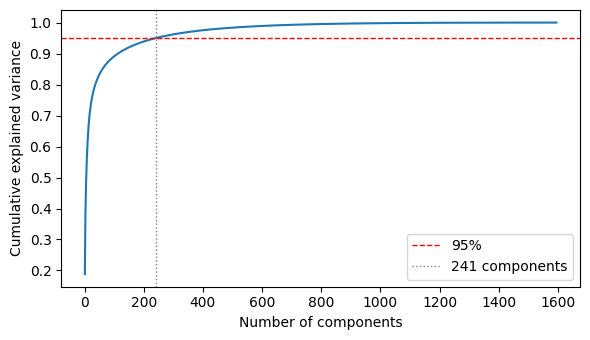

In [11]:
scaler = StandardScaler().fit(X_train_5)
X_train_scaled = scaler.transform(X_train_5)
X_val_scaled = scaler.transform(X_val_5)
X_test_scaled = scaler.transform(X_test_5)

# PCA: keep enough components to explain 95% of the training variance
VARIANCE_TARGET = 0.95
pca_full = PCA(random_state=RANDOM_SEED).fit(X_train_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cumulative, VARIANCE_TARGET) + 1)

pca = PCA(n_components=n_components, random_state=RANDOM_SEED).fit(X_train_scaled)
X_train_pca_5 = pca.transform(X_train_scaled)
X_val_pca_5 = pca.transform(X_val_scaled)
X_test_pca_5 = pca.transform(X_test_scaled)
print(f"PCA: 2048 -> {n_components} components "
      f"({pca.explained_variance_ratio_.sum():.2%} variance explained)")

plt.figure(figsize=(6, 3.5))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative)
plt.axhline(VARIANCE_TARGET, color="r", ls="--", lw=1, label=f"{VARIANCE_TARGET:.0%}")
plt.axvline(n_components, color="gray", ls=":", lw=1, label=f"{n_components} components")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
plt.legend(); plt.tight_layout(); plt.show()

## 5. Classification

We are going to test 3 different models, SVM, Random Forest and XGBoost. For each one, we test the three different types of labels for each model. For the best performing one, we perform hyperparameter tuning and use the best model for comparison.

### 5.1. SVM

In [12]:
svm_classifier = SVC(kernel="rbf",
                     class_weight="balanced", probability=True,
                     random_state=RANDOM_SEED)

# Binary
svm_classifier.fit(X_train_pca_binary, y_train_binary)
y_pred = svm_classifier.predict(X_test_pca_binary)
y_pred_binary = y_pred
y_score = svm_classifier.predict_proba(X_test_pca_binary)[:, 1]
balanced_accuracy = balanced_accuracy_score(y_test_binary, y_pred)
f1 = f1_score(y_test_binary, y_pred)
mae = mean_absolute_error(y_test_binary, y_pred)  # for binary labels = misclassification rate
auc = roc_auc_score(y_test_binary, y_score)
print("Binary")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test F1 Score:          {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test ROC AUC:           {auc:.4f}")
print("\n")

# 3-class
svm_classifier.fit(X_train_pca_3, y_train_3)
y_pred = svm_classifier.predict(X_test_pca_3)
y_score = svm_classifier.predict_proba(X_test_pca_3)
balanced_accuracy = balanced_accuracy_score(y_test_3, y_pred)
f1 = f1_score(y_test_3, y_pred, average="macro")
mae = mean_absolute_error(y_test_3, y_pred)
auc = roc_auc_score(y_test_3, y_score, multi_class="ovr", average="macro")
print("3-class")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test Macro F1 Score:    {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test Macro ROC AUC:     {auc:.4f}")
print("\n")

# 5-class
svm_classifier.fit(X_train_pca_5, y_train_5)
y_pred = svm_classifier.predict(X_test_pca_5)
y_score = svm_classifier.predict_proba(X_test_pca_5)
balanced_accuracy = balanced_accuracy_score(y_test_5, y_pred)
f1 = f1_score(y_test_5, y_pred, average="macro")
mae = mean_absolute_error(y_test_5, y_pred)
auc = roc_auc_score(y_test_5, y_score, multi_class="ovr", average="macro")
print("5-class")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test Macro F1 Score:    {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test Macro ROC AUC:     {auc:.4f}")

Binary
Test Balanced Accuracy: 0.8066
Test F1 Score:          0.7086
Test MAE:               0.2016
Test ROC AUC:           0.8742


3-class
Test Balanced Accuracy: 0.5178
Test Macro F1 Score:    0.4846
Test MAE:               0.8035
Test Macro ROC AUC:     0.7047


5-class
Test Balanced Accuracy: 0.4162
Test Macro F1 Score:    0.3402
Test MAE:               0.8526
Test Macro ROC AUC:     0.7304


The best results are clearly associated with the binary classification.

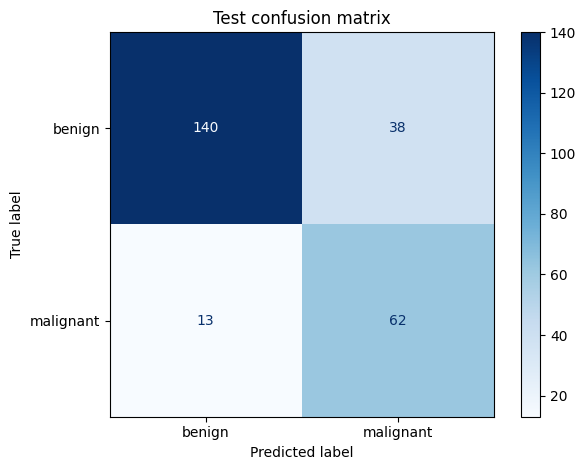

In [13]:
ConfusionMatrixDisplay(confusion_matrix(y_test_binary, y_pred_binary), display_labels=["benign", "malignant"]).plot(cmap="Blues")
plt.title("Test confusion matrix"); plt.tight_layout(); plt.show()

In [14]:
gamma_scale = 1.0 / (X_train_pca_binary.shape[1] * X_train_pca_binary.var())  # same as gamma="scale"
grid = [(C, gamma_scale * g) for C in [0.1, 1, 10, 100] for g in [0.1, 0.3, 1, 3]]

rows = []
for C, gamma in grid:
    clf = SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced", random_state=RANDOM_SEED)
    clf.fit(X_train_pca_binary, y_train_binary)
    pred = clf.predict(X_val_pca_binary)
    rows.append({"C": C, "gamma": gamma,
                 "val_balanced_acc": balanced_accuracy_score(y_val_binary, pred),
                 "val_f1": f1_score(y_val_binary, pred)})
tuning = pd.DataFrame(rows).sort_values("val_balanced_acc", ascending=False).reset_index(drop=True)
display(tuning.head(8))
best = tuning.iloc[0]
print(f"Best: C={best.C}, gamma={best.gamma:.3g} (val balanced acc={best.val_balanced_acc:.4f})")

svm_classifier = SVC(kernel="rbf", #C=best.C, gamma=best.gamma,
                     class_weight="balanced", probability=True,
                     random_state=RANDOM_SEED)

# Binary
svm_classifier.fit(X_train_pca_binary, y_train_binary)
y_pred = svm_classifier.predict(X_test_pca_binary)
y_pred_binary = y_pred
y_score = svm_classifier.predict_proba(X_test_pca_binary)[:, 1]
balanced_accuracy = balanced_accuracy_score(y_test_binary, y_pred)
f1 = f1_score(y_test_binary, y_pred)
mae = mean_absolute_error(y_test_binary, y_pred)  # for binary labels = misclassification rate
auc = roc_auc_score(y_test_binary, y_score)
recall = recall_score(y_test_binary, y_pred)
print("Binary")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test F1 Score:          {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test ROC AUC:           {auc:.4f}")
print("\n")

,C,gamma,val_balanced_acc,val_f1
0,1.0,0.000051,0.819345,0.744444
1,1.0,0.000154,0.810512,0.733333
2,10.0,0.000051,0.804488,0.726257
3,1.0,0.000514,0.801679,0.722222
4,100.0,0.000154,0.799682,0.716578
5,100.0,0.000051,0.798464,0.719101
6,0.1,0.000154,0.796873,0.712766
7,10.0,0.000154,0.792846,0.711111


Best: C=1.0, gamma=5.14e-05 (val balanced acc=0.8193)
Binary
Test Balanced Accuracy: 0.8066
Test F1 Score:          0.7086
Test MAE:               0.2016
Test ROC AUC:           0.8742




### 5.2. Random Forest

In [15]:
rf = RandomForestClassifier(random_state=RANDOM_SEED)

# Binary
rf.fit(X_train_pca_binary, y_train_binary)
y_pred = rf.predict(X_test_pca_binary)
y_score = rf.predict_proba(X_test_pca_binary)[:, 1]
balanced_accuracy = balanced_accuracy_score(y_test_binary, y_pred)
f1 = f1_score(y_test_binary, y_pred)
mae = mean_absolute_error(y_test_binary, y_pred)  # for binary labels = misclassification rate
auc = roc_auc_score(y_test_binary, y_score)
print("Binary")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test F1 Score:          {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test ROC AUC:           {auc:.4f}")
print("\n")

# 3-class
rf.fit(X_train_pca_3, y_train_3)
y_pred = rf.predict(X_test_pca_3)
y_score = rf.predict_proba(X_test_pca_3)
balanced_accuracy = balanced_accuracy_score(y_test_3, y_pred)
f1 = f1_score(y_test_3, y_pred, average="macro")
mae = mean_absolute_error(y_test_3, y_pred)
auc = roc_auc_score(y_test_3, y_score, multi_class="ovr", average="macro")
print("3-class")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test Macro F1 Score:    {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test Macro ROC AUC:     {auc:.4f}")
print("\n")

# 5-class
rf.fit(X_train_pca_5, y_train_5)
y_pred = rf.predict(X_test_pca_5)
y_score = rf.predict_proba(X_test_pca_5)
balanced_accuracy = balanced_accuracy_score(y_test_5, y_pred)
f1 = f1_score(y_test_5, y_pred, average="macro")
mae = mean_absolute_error(y_test_5, y_pred)
auc = roc_auc_score(y_test_5, y_score, multi_class="ovr", average="macro")
print("5-class")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test Macro F1 Score:    {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test Macro ROC AUC:     {auc:.4f}")

Binary
Test Balanced Accuracy: 0.7842
Test F1 Score:          0.7132
Test MAE:               0.1462
Test ROC AUC:           0.8745


3-class
Test Balanced Accuracy: 0.5136
Test Macro F1 Score:    0.4680
Test MAE:               0.6214
Test Macro ROC AUC:     0.7056


5-class
Test Balanced Accuracy: 0.2483
Test Macro F1 Score:    0.2275
Test MAE:               0.6012
Test Macro ROC AUC:     0.7004


In [16]:
# One again, binary classification outperforms
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'bootstrap': [True, False]
}

grid_search = GridSearchCV(RandomForestClassifier(), param_grid=param_grid, cv=5)
grid_search.fit(X_train_pca_binary, y_train_binary)

print("Best Parameters:", grid_search.best_params_)
print("Best Estimator:", grid_search.best_estimator_)

Best Parameters: {'bootstrap': False, 'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}
Best Estimator: RandomForestClassifier(bootstrap=False, max_depth=20, min_samples_leaf=2,
                       n_estimators=200)


Binary
Test Balanced Accuracy: 0.8035
Test F1 Score:          0.7338
Test MAE:               0.1462
Test ROC AUC:           0.8830


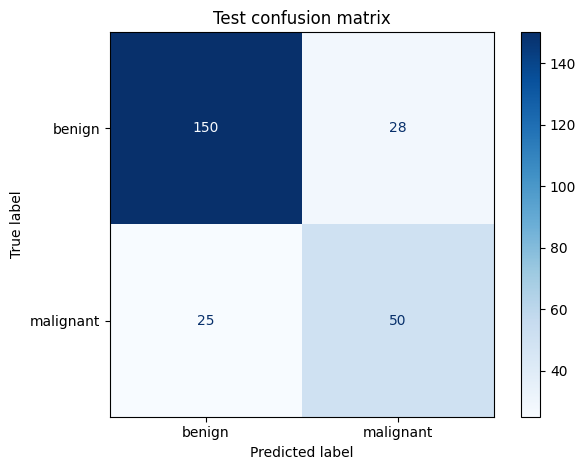

In [19]:
rf = RandomForestClassifier(bootstrap=False, max_depth=None, min_samples_leaf=1, min_samples_split=5, n_estimators=200, random_state=RANDOM_SEED)
rf.fit(X_train_pca_binary, y_train_binary)
y_pred_rf = rf.predict(X_test_pca_binary)
y_score_rf = rf.predict_proba(X_test_pca_binary)[:, 1]
balanced_accuracy = balanced_accuracy_score(y_test_binary, y_pred_rf)
f1 = f1_score(y_test_binary, y_pred)
mae = mean_absolute_error(y_test_binary, y_pred)  # for binary labels = misclassification rate
auc = roc_auc_score(y_test_binary, y_score)
print("Binary")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test F1 Score:          {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test ROC AUC:           {auc:.4f}")

ConfusionMatrixDisplay(confusion_matrix(y_test_binary, y_pred_binary), display_labels=["benign", "malignant"]).plot(cmap="Blues")
plt.title("Test confusion matrix"); plt.tight_layout(); plt.show()

### 5.3. XGBoost

Binary
Test Balanced Accuracy: 0.7547
Test F1 Score:          0.6536
Test MAE:               0.2095
Test ROC AUC:           0.8469


3-class
Test Balanced Accuracy: 0.5407
Test Macro F1 Score:    0.5046
Test MAE:               0.6301
Test Macro ROC AUC:     0.7035


5-class
Test Balanced Accuracy: 0.2989
Test Macro F1 Score:    0.2942
Test MAE:               0.6185
Test Macro ROC AUC:     0.6970


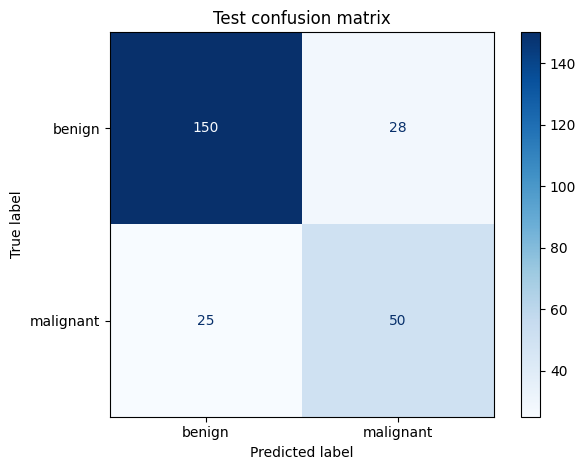

In [18]:
# Binary
xgb_train_binary = xgb.DMatrix(X_train_pca_binary, label=y_train_binary)
xgb_test_binary = xgb.DMatrix(X_test_pca_binary, label=y_test_binary)
model_binary = xgb.train(
    params={"objective": "binary:logistic"},
    dtrain=xgb_train_binary,
)
y_score_binary = model_binary.predict(xgb_test_binary)
y_pred_binary = (y_score_binary >= 0.5).astype(np.int64)
balanced_accuracy = balanced_accuracy_score(y_test_binary, y_pred_binary)
f1 = f1_score(y_test_binary, y_pred_binary)
mae = mean_absolute_error(y_test_binary, y_pred_binary)
auc = roc_auc_score(y_test_binary, y_score_binary)
print("Binary")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test F1 Score:          {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test ROC AUC:           {auc:.4f}")
print("\n")

# 3-class
xgb_train_3 = xgb.DMatrix(X_train_pca_3, label=y_train_3)
xgb_test_3 = xgb.DMatrix(X_test_pca_3, label=y_test_3)
model_3 = xgb.train(
    params={"objective": "multi:softprob", "num_class": 3},
    dtrain=xgb_train_3,
)
y_score_3 = model_3.predict(xgb_test_3)
y_pred_3 = np.argmax(y_score_3, axis=1)
balanced_accuracy = balanced_accuracy_score(y_test_3, y_pred_3)
f1 = f1_score(y_test_3, y_pred_3, average="macro")
mae = mean_absolute_error(y_test_3, y_pred_3)
auc = roc_auc_score(y_test_3, y_score_3, multi_class="ovr", average="macro")
print("3-class")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test Macro F1 Score:    {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test Macro ROC AUC:     {auc:.4f}")
print("\n")

# 5-class labels are encoded 0..4 for XGBoost, then mapped back to ratings 1..5.
le = LabelEncoder()
y_train_5_enc = le.fit_transform(y_train_5)
y_test_5_enc = le.transform(y_test_5)
xgb_train_5 = xgb.DMatrix(X_train_pca_5, label=y_train_5_enc)
xgb_test_5 = xgb.DMatrix(X_test_pca_5, label=y_test_5_enc)
model_5 = xgb.train(
    params={"objective": "multi:softprob", "num_class": 5},
    dtrain=xgb_train_5,
)
y_score_5 = model_5.predict(xgb_test_5)
y_pred_5_enc = np.argmax(y_score_5, axis=1)
y_pred_5 = le.inverse_transform(y_pred_5_enc)
balanced_accuracy = balanced_accuracy_score(y_test_5, y_pred_5)
f1 = f1_score(y_test_5, y_pred_5, average="macro")
mae = mean_absolute_error(y_test_5, y_pred_5)
auc = roc_auc_score(y_test_5_enc, y_score_5, multi_class="ovr", average="macro")
print("5-class")
print(f"Test Balanced Accuracy: {balanced_accuracy:.4f}")
print(f"Test Macro F1 Score:    {f1:.4f}")
print(f"Test MAE:               {mae:.4f}")
print(f"Test Macro ROC AUC:     {auc:.4f}")

ConfusionMatrixDisplay(confusion_matrix(y_test_binary, y_pred_binary), display_labels=["benign", "malignant"]).plot(cmap="Blues")
plt.title("Test confusion matrix"); plt.tight_layout(); plt.show()